# Model A v2: spotting reports that look wrong

**IRIS · Team Nex · PJDSC 2026**

Model A asks one question for every province or city, every week: *is this week's dengue count suspiciously low?*
A suspiciously low count can mean cases were not reported (a missing or partial submission, a typing error, a
broken connection), and that is what IRIS must catch.

This notebook explains **Model A v2** and shows its results. It uses the tested code in `pipeline/iris_pipeline/`,
so every number matches `pipeline/outputs/model_a_v2/eval_report.md`. The original v1 notebook, `model_a.ipynb`,
is kept unchanged as the baseline.

**Contents**
1. Data and checks
2. v1 recap, and proof the new code reproduces it
3. What v2 changes, shown on one city
4. Choosing the v2 variant using 2016–2019 only
5. Threshold and `p_fail`, frozen on 2019
6. The 2020 test, scored once
7. Region-wide (hub) evidence
8. Roadmap targets and the bottom line
9. What Model A hands to Model B

In [1]:
# Find the tested pipeline (works in PJDS/ and in the IRIS repo's "Model A/" folder) and load it.
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
PIPELINE = None
for base in [Path.cwd(), *Path.cwd().parents]:
    for cand in (base / "pipeline", base / "Model A" / "pipeline", base / "MODEL A" / "pipeline"):
        if (cand / "iris_pipeline").is_dir():
            PIPELINE = cand
            break
    if PIPELINE:
        break
if PIPELINE is None:
    raise FileNotFoundError("Can't find the pipeline/ folder. Open this notebook from inside the repository.")
sys.path.insert(0, str(PIPELINE))

import iris_pipeline  # sets single-threaded maths before numpy loads
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from iris_pipeline import config, data
from iris_pipeline.paths import MODEL_A_V2_DIR, OUT_DIR, V1_OUT_DIR

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
print("pipeline:", PIPELINE)
print("outputs: ", OUT_DIR)

pipeline: C:\Users\John Vincent Doria\Desktop\PJDS\pipeline
outputs:  C:\Users\John Vincent Doria\Desktop\PJDS\pipeline\outputs


In [2]:
# The heavy runs live in the pipeline (python -m iris_pipeline all, about 25 min).
# This notebook reads their saved outputs and runs only small live demos. Set to True to rebuild everything first.
RUN_PIPELINE = False
if RUN_PIPELINE:
    from iris_pipeline.cli import main
    main(["all"])

## 1. Data and checks

Both models read only the **cleaned** files: corrected place names and regions, and a full calendar of weeks in
which a week that was due but not received stays a row marked `missing`. `data.load()` checks the files against
the counts in the cleaning report and stops if anything differs. The **answer key** (which rows are known errors)
is kept in separate tables and never reaches the model.

In [3]:
inp = data.load()   # raises if any check fails
X = inp.X_dengue
print(f"{X.location_id.nunique()} places, {X.region_id.nunique()} regions, {X.week_start.nunique()} weeks "
      f"({X.week_start.min():%Y-%m-%d} to {X.week_start.max():%Y-%m-%d})")
display(X.report_status.value_counts().rename("location-weeks").to_frame())
known = data.fl(inp.Y_dengue, "swap_cases_deaths")
print(f"Known real errors (answer key): {int(known.sum())} swapped rows "
      f"(cases and deaths swapped, so a real count became 0-3), plus 3 region-wide gaps.")
print("Model inputs contain no answer-key columns:", sorted(set(X.columns)))

126 places, 17 regions, 262 weeks (2016-01-10 to 2021-01-10)


,location-weeks
report_status,
reported,32701
missing,259
not_in_source,52


Known real errors (answer key): 581 swapped rows (cases and deaths swapped, so a real count became 0-3), plus 3 region-wide gaps.
Model inputs contain no answer-key columns: ['cases', 'location', 'location_id', 'mw', 'mw_year', 'region', 'region_id', 'report_status', 'week_start']


## 2. v1 recap, and proof the new code reproduces it

**v1** fits, for each place, a negative binomial count model with trend, season and holidays, using only earlier
weeks (refitted every 4 weeks). It flags a week when the count is far below what the model expected.

Before changing anything, v1 was copied into the pipeline. Below, the copy re-scores five places and is compared
with the published v1 `scores.csv`. The only differences come from the file storing 6 significant digits.

In [4]:
from iris_pipeline.model_a.run import run_weekly

places = sorted(X.location_id.unique())[::25][:5]
d, _ = run_weekly(X[X.location_id.isin(places)], "location_id", inp.cal, config.V1, config.options("v1"), workers=1)
v1 = pd.read_csv(V1_OUT_DIR / "scores.csv", parse_dates=["period_start"])
m = d.merge(v1[v1.disease == "dengue"], left_on=["location_id", "week_start"], right_on=["location_id", "period_start"],
            suffixes=("", "_published"))
rows = []
for col in ("expected", "p_low", "pi_low", "pi_high"):
    a, b = m[col].to_numpy(float), m[col + "_published"].to_numpy(float)
    ok = ~np.isnan(a)
    rows.append({"column": col, "rows compared": int(ok.sum()),
                 "max relative difference": float(np.max(np.abs(a[ok] - b[ok]) / np.maximum(np.abs(b[ok]), 1e-12)))})
display(pd.DataFrame(rows))

,column,rows compared,max relative difference
0,expected,1270,4.782e-06
1,p_low,1259,4.728e-06
2,pi_low,1270,0.000e+00
3,pi_high,1270,0.000e+00


## 3. What v2 changes, shown on one city

v1's weak spots, from its own report:

- **It could not follow a real drop.** In 2020, COVID-19 cut dengue reporting sharply. v1 kept expecting the
  usual season and flagged 12% of normal weeks (budget: 1%).
- **Its "90% range" was too narrow.** Only 73–79% of normal weeks fell inside it.

v2 adds three things to the same model:

| addition | what it does |
|---|---|
| recent level | a term for the median of the last 4 usable reports, so the expectation follows real changes. A week that already looks suspicious is not used, so an outage can't hide itself. |
| parameter uncertainty | the range widens when the model's own estimates are uncertain |
| year-to-year size | the range widens by how much epidemic size varied between past years |

Pasig City is where v1 raised the most false alarms in 2020. Both versions are scored live below.

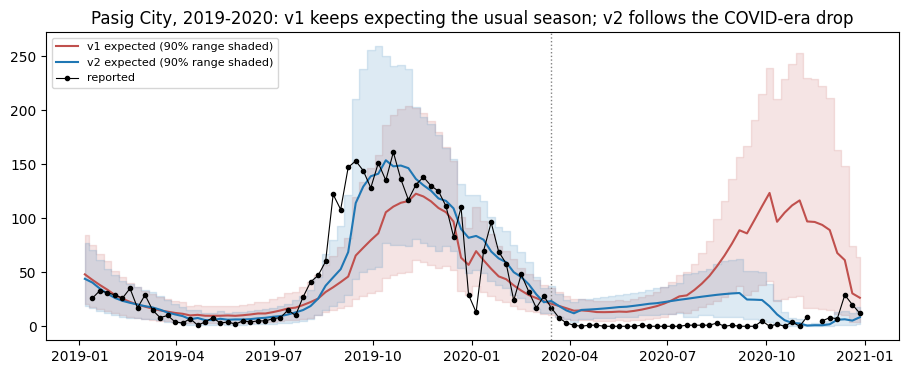

In [5]:
from iris_pipeline.model_a.countmodel import CountModel, design

loc = "NCR-PASIG_CITY"
g = X[X.location_id == loc].sort_values("week_start").reset_index(drop=True)
y = np.where(g.report_status.eq("reported"), g.cases, np.nan).astype(float)
hol = inp.cal.set_index("week_start")[["holy_week", "christmas_newyear"]].reindex(g.week_start).reset_index(drop=True)
Xd = design(len(g), config.V1["PERIODS_PER_YEAR"]["week"], hol)
fits = {name: CountModel(config.V1, config.options(name)).score_series(y, Xd, loc, [], years=g.week_start.dt.year.to_numpy())
        for name in ("v1", config.MODEL_A_VARIANT)}

sel = g.week_start.dt.year.isin([2019, 2020]).to_numpy()
fig, ax = plt.subplots(figsize=(11, 4))
for (name, s), color in zip(fits.items(), ("#c0504d", "#1f77b4")):
    ax.fill_between(g.week_start[sel], s.pi_low[sel], s.pi_high[sel], color=color, alpha=0.15, step="mid")
    ax.plot(g.week_start[sel], s.expected[sel], color=color, lw=1.5, label=f"{'v1' if name == 'v1' else 'v2'} expected (90% range shaded)")
ax.plot(g.week_start[sel], y[sel], color="black", marker=".", lw=0.8, label="reported")
ax.axvline(pd.Timestamp("2020-03-15"), color="grey", ls=":", lw=1)
ax.set_title("Pasig City, 2019-2020: v1 keeps expecting the usual season; v2 follows the COVID-era drop")
ax.legend(fontsize=8)
plt.show()

## 4. Choosing the v2 variant using 2016–2019 only

Eight variants were compared **before 2020 was looked at**, with a rule fixed in advance:
1. the 90% range must hold 85–95% of normal weeks in 2017–2019;
2. among those, take the best 2019 recall on simulated failures (zeros, partial reports, outages) at a 1% false-alarm rate.

The choice was written to `selection.json` before any 2020 number was computed.

In [6]:
sel_table = pd.read_csv(MODEL_A_V2_DIR / "selection_2016_2019.csv")
choice = json.loads((MODEL_A_V2_DIR / "selection.json").read_text(encoding="utf-8"))
display(sel_table[["candidate", "coverage90_2017_2019", "inj_recall_2019", "inj_far_2019", "swap_recall_2016", "swap_recall_2017"]]
        .rename(columns={"coverage90_2017_2019": "inside 90% range, 2017-19", "inj_recall_2019": "2019 simulated failures caught",
                         "inj_far_2019": "2019 false alarms", "swap_recall_2016": "2016 real swaps caught",
                         "swap_recall_2017": "2017 real swaps caught"}))
display(Markdown(f"**Chosen: `{choice['chosen']}`**: {choice['reason']}."))

,candidate,"inside 90% range, 2017-19",2019 simulated failures caught,2019 false alarms,2016 real swaps caught,2017 real swaps caught
0,v1,0.750,0.369,0.008,0.391,0.621
1,v1+uncertainty,0.814,0.366,0.006,0.498,0.727
2,recent1,0.826,0.349,0.005,0.138,0.379
3,recent1+uncertainty,0.859,0.398,0.005,0.178,0.449
4,recent2+uncertainty,0.847,0.448,0.005,0.311,0.540
5,recent1x+uncertainty,0.832,0.352,0.004,0.164,0.384
6,recent2x+uncertainty,0.826,0.386,0.005,0.227,0.470
7,covid+uncertainty,0.814,0.366,0.006,0.498,0.727


**Chosen: `recent1+uncertainty`**: coverage 0.859 is inside [0.85, 0.95] and it has the best 2019 injected-failure recall (0.398) among those that are.

## 5. Threshold and `p_fail`, frozen on 2019

- **Threshold.** A week is flagged when `p_low < tau`. `p_low` is the chance of a count this low if reporting were
  normal. `tau` is the value with the best F1 on 2019's simulated failures while flagging at most 1% of real 2019
  normal weeks.
- **`p_fail`.** The chance that a flagged week is a *real* failure: an isotonic regression fitted on 2019, then
  adjusted to the real error rate seen in 2016–2018. It is checked on 2020, which was not used to fit it.

v2 threshold: p_low < 0.000121   (v1: 0.000903)


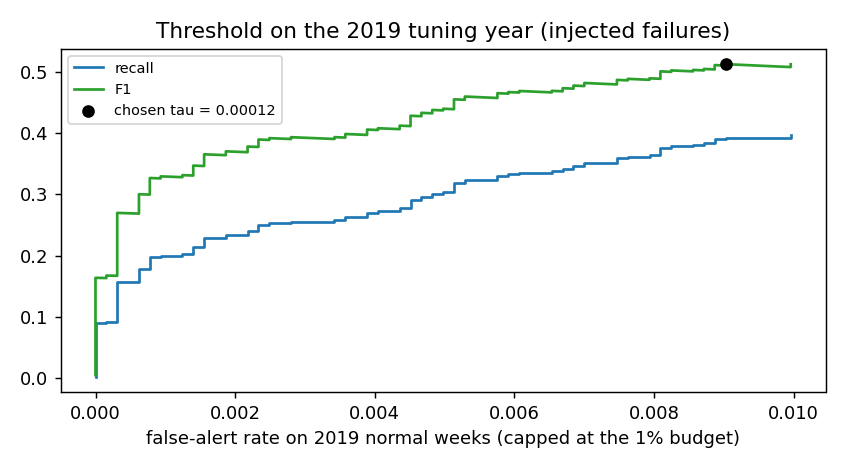

**`p_fail` reliability on 2020** (predicted probability vs the share that were real errors)

,bin,rows,mean_p_fail,observed_failure_share
0,"(-0.001, 0.01]",4226,0.003,0.007
1,"(0.01, 0.05]",1144,0.032,0.045
2,"(0.05, 0.1]",266,0.084,0.045
3,"(0.1, 0.25]",300,0.154,0.097
4,"(0.25, 0.5]",391,0.424,0.079
5,"(0.5, 1.0]",179,0.889,0.022


In [7]:
cfg = json.loads((MODEL_A_V2_DIR / "config.json").read_text(encoding="utf-8"))
metrics = json.loads((MODEL_A_V2_DIR / "metrics.json").read_text(encoding="utf-8"))
print(f"v2 threshold: p_low < {cfg['TAU_model_a_v2']:.3g}   (v1: {cfg['TAU_model_a_v1']:.3g})")
display(Image(filename=str(MODEL_A_V2_DIR / "figures" / "3_threshold_curve_2019.png"), width=520))
rel = pd.DataFrame(list(metrics["pfail_reliability"].values())[0])
display(Markdown("**`p_fail` reliability on 2020** (predicted probability vs the share that were real errors)"))
display(rel)

## 6. The 2020 test, scored once

Thresholds are frozen; 2020 has not been used for any choice. 95% intervals are cluster-bootstrap intervals, with
whole places resampled. Three sets of failures are used: the **real swapped reports**, the **real region-wide gap
filled with zeros**, and **simulated failures** injected into the real data.

,failure set,method,positives,recall (95% CI),false-alert rate (95% CI),precision,F1,AUC
0,2020: real swaps,Model A v1,158,0.494 (0.377–0.618),0.121 (0.097–0.149),0.092,0.156,0.842
1,2020: real swaps,Model A v2,158,0.089 (0.010–0.175),0.055 (0.036–0.077),0.039,0.054,0.790
2,2020: real swaps,Rolling median,158,0.032 (0.000–0.070),0.004 (0.002–0.006),0.167,0.053,0.700
3,2020: real swaps,EWMA,158,0.044 (0.014–0.075),0.006 (0.004–0.008),0.156,0.069,0.800
4,2020: real swaps,CUSUM,158,0.013 (0.000–0.044),0.038 (0.021–0.060),0.008,0.010,0.381
5,2020: regional gap filled with 0,Model A v1,46,0.152 (0.065–0.275),0.084 (0.066–0.108),0.014,0.025,0.732
6,2020: regional gap filled with 0,Model A v2,46,0.000 (0.000–0.000),0.031 (0.018–0.048),0.000,0.000,0.697
7,2020: regional gap filled with 0,Rolling median,46,0.000 (0.000–0.000),0.003 (0.001–0.004),0.000,0.000,0.574
8,2020: regional gap filled with 0,EWMA,46,0.000 (0.000–0.000),0.003 (0.001–0.004),0.000,0.000,0.731
9,2020: regional gap filled with 0,CUSUM,46,0.022 (0.000–0.070),0.040 (0.018–0.066),0.004,0.007,0.260


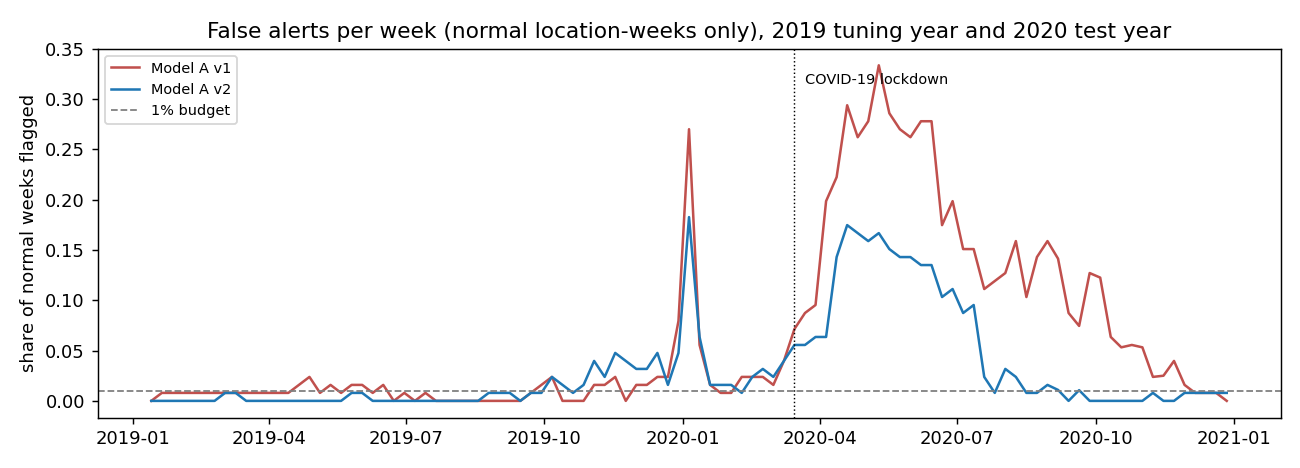

In [8]:
head = pd.DataFrame(metrics["headline"])
display(head[["failure set", "method", "positives", "recall (95% CI)", "false-alert rate (95% CI)", "precision", "F1", "AUC"]])
display(Image(filename=str(MODEL_A_V2_DIR / "figures" / "1_weekly_false_alerts_2019_2020.png"), width=900))

The figure shows the trade-off. v2 adjusts after the COVID-19 drop (blue comes back down near the budget in the
last months of 2020, while v1 stays high), but neither version holds 1% through April–June 2020. Following the low level also makes a zero
look less unusual, so v2 catches fewer of the real 2020 swaps than v1.

> 2020 was scored twice. The first run had a bug in how the threshold cap was counted, which was visible on 2019
> alone. It was fixed and both runs are reported in `eval_report.md`; nothing was tuned on 2020.

## 7. Region-wide (hub) evidence

When a whole region goes quiet at once, the cause is more likely shared: a hub, a server, a typhoon. v1 pooled the
places of a region as if they were independent witnesses (Fisher), so a real region-wide drop looked like
overwhelming evidence of failure. v2 pools them allowing for the fact that places move together (Stouffer,
correlation-adjusted).

,model,pooling,failure set,region-weeks,detected,false region alerts (clean region-weeks)
0,Model A v1 (as in its report: Fisher p < tau),Fisher,real swaps 2020 (test),24,1.000,0.619
2,Model A v1,Fisher,real swaps 2020 (test),24,0.750,0.178
3,Model A v1,Fisher,"regional gap filled with 0, 2017 + 2020",11,0.545,0.050
4,Model A v1,Fisher,"injected region outage, 2019 + 2020",6,0.833,0.066
6,Model A v1,"Stouffer, correlation-adjusted",real swaps 2020 (test),24,0.792,0.180
7,Model A v1,"Stouffer, correlation-adjusted","regional gap filled with 0, 2017 + 2020",11,0.545,0.053
8,Model A v1,"Stouffer, correlation-adjusted","injected region outage, 2019 + 2020",6,0.833,0.072
10,Model A v2,Fisher,real swaps 2020 (test),24,0.375,0.111
11,Model A v2,Fisher,"regional gap filled with 0, 2017 + 2020",11,0.455,0.027
12,Model A v2,Fisher,"injected region outage, 2019 + 2020",6,0.833,0.037


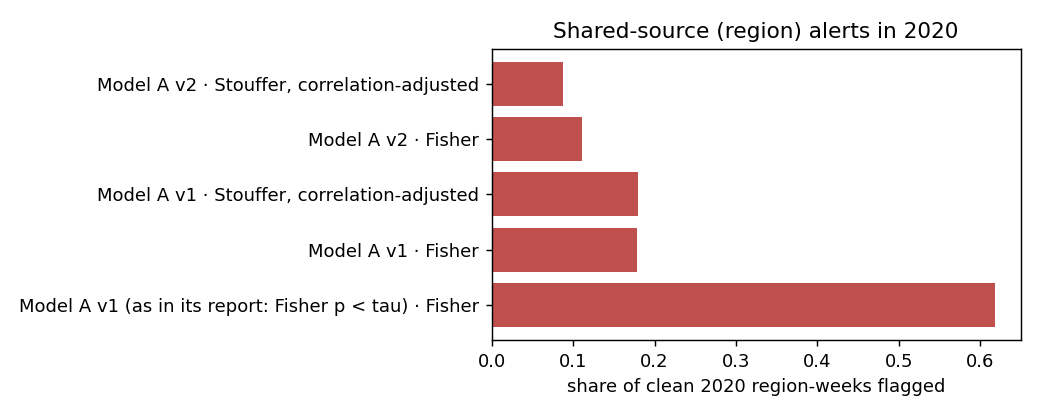

In [9]:
region = pd.DataFrame(metrics["region"])
display(region[region["failure set"].str.contains("2020")])
display(Image(filename=str(MODEL_A_V2_DIR / "figures" / "6_region_false_alerts_2020.png"), width=720))

## 8. Roadmap targets and the bottom line

In [10]:
display(pd.DataFrame(metrics["done_when"]))

,target (roadmap step 2),Model A v1,Model A v2,met
0,2020 false-alert rate close to 1% (≤ 2%),0.121,0.055,no
1,2020 recall on real swaps well above the basel...,0.494,0.089 (CI 0.010–0.175),no
2,"85–95% of normal weeks inside the 90% range, 2...",0.750,0.859,yes
3,"85–95% of normal weeks inside the 90% range, 2...",0.556,0.793,no


**Bottom line.** v2 is a different trade-off, not a better model on every count. It cuts false alarms
(individual weeks 12% → 5.5%, regions 62% → 9%), ranks simulated failures better (AUC 0.77 → 0.85) and gives
honest ranges in normal years. But it catches far fewer of the real 2020 swaps. The 2020 COVID drop remains the
hardest case. One lesson from the real errors is that a plain zero carries more evidence than v2 gives it: a
candidate for v3, to be chosen on pre-2020 data.

## 9. What Model A hands to Model B

`scores_v2.csv` is the contract between the two models (`pipeline/CONTRACT.md`). Each row is one place-week with
the evidence Model B needs: expected count and range, `p_low`, `p_fail`, `shortfall` (cases likely missing),
`hub_id` and `hub_p`. `validate()` checks every rule before anything is written or read.

In [11]:
from iris_pipeline.contract import validate
from iris_pipeline.model_a.v2 import read_scores

scores = read_scores(MODEL_A_V2_DIR / "scores_v2.csv")
validate(scores)
print(f"scores_v2.csv passes the contract: {len(scores):,} rows, run {scores.run_id.iloc[0]}")
week = scores[(scores.disease == "dengue") & (scores.period_start == "2020-11-15") & (scores.flag == 1)]
display(week.sort_values("p_fail", ascending=False)[["location_id", "hub_id", "cases", "expected", "pi_low", "pi_high",
                                                     "p_low", "p_fail", "shortfall", "hub_p"]].head(10))

scores_v2.csv passes the contract: 37,866 rows, run 20261023T075030Z-73b3e833


,location_id,hub_id,cases,expected,pi_low,pi_high,p_low,p_fail,shortfall,hub_p


## Limits

- Flags are **leads to verify**, not confirmed errors. The real labels are the errors found during cleaning;
  other errors are unknown and count as normal weeks.
- Simulated failures are simulated. `p_fail` is calibrated on dengue; for other diseases it is reported but not validated.
- The hub is the region's RESU, because real reporting pathways are not available (the simulated network in
  `model_b_v2.ipynb` tests real hub structure).